# DC Power Flow

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## As a function of load voltage
For the circuit shown below
1. plot $I$ and $P_{L}$ as a function of $V_{L}$.
Assume $E$ = 1.0 pu and $R_{s}$ = 0.1 pu.

1. What value(s) of $V_{L}$ is the power 1 pu ?
2. What is the maximum power transfer possible?       Why?
3. What is the maximum power transfer possible for 95% efficiency? What is $V_{L}$ ?
4. If $E$ now increases to 1.05 pu, what is the power in the load, for the conditions of part 4.


Setup the circuit parameters

In [2]:
E = 1.0 # Voltage source in pu
Rs = 0.1 # resistance in pu

### 1) Plot $I$ and $P_{L}$ as a function of $V_{L}$

Create an array of the load voltage to be used in the calculations

In [4]:
# TODO: create an array of the load voltages over the range 0 to 1.0 pu
Vl = np.linspace(0, 1.0, 1001)

Calculate the current and power in the load for each value of $V_{L}$

In [ ]:
#TODO: calculate the current and power in the load.
# KVL around the loop: E = I*Rs + VL, so the line takes whatever voltage the load doesn't
I = (E - Vl) / Rs    # current through the line and the load, pu
PL = Vl * I          # power delivered to the load, pu
eta = Vl / E         # efficiency = power into load / power from source = (VL*I) / (E*I)

Store the results in a pandas dataframe for easy analysis and plotting

In [6]:
results = pd.DataFrame({'VL': Vl, 'I': I, 'PL': PL})

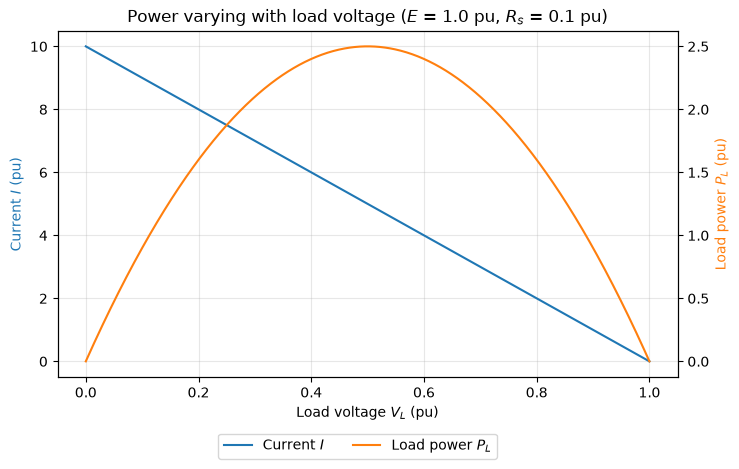

In [9]:
# TODO: plot the results
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(results['VL'], results['I'], color='tab:blue', label='Current $I$')
ax1.set_xlabel('Load voltage $V_L$ (pu)')
ax1.set_ylabel('Current $I$ (pu)', color='tab:blue')

ax2 = ax1.twinx()   # second y-axis for power, as on the slide
ax2.plot(results['VL'], results['PL'], color='tab:orange', label='Load power $P_L$')
ax2.set_ylabel('Load power $P_L$ (pu)', color='tab:orange')

ax1.set_title('Power varying with load voltage ($E$ = 1.0 pu, $R_s$ = 0.1 pu)')
ax1.grid(alpha=0.3)
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2)
plt.show()

### 2) When is the power in the load equal to 1 pu ?

In [20]:
# TODO: solve the quadratic equation for V_L
# P_L = VL*(E - VL)/Rs = P   ->   VL**2 - E*VL + P*Rs = 0   (a quadratic in VL)
P = 1.0                                   # target load power, pu
VL_roots = np.roots([1, -E, P * Rs])      # coefficients a, b, c of a*VL**2 + b*VL + c = 0
print("VL for P_L = 1 pu:  ", VL_roots)
print("Efficiency at each: ", VL_roots / E)

VL for P_L = 1 pu:   [0.88729833 0.11270167]
Efficiency at each:  [0.88729833 0.11270167]


### 3) What is the maximum power transfer possible? Why?

In [21]:
# inspect from the results
print(results.loc[results['PL'].idxmax()])   # the row with the largest load power

# differentiate the power equation with respect to VL and set it equal to zero. Solve for VL.
# P_L = (E*VL - VL**2)/Rs   ->   dP_L/dVL = (E - 2*VL)/Rs = 0   ->   VL = E/2
VL_max = E / 2
P_max = VL_max * (E - VL_max) / Rs           # = E**2 / (4*Rs)
print(f"\nAnalytical: VL = {VL_max} pu, P_max = {P_max:.2f} pu, efficiency = {VL_max / E:.0%}")

VL    0.5
I     5.0
PL    2.5
Name: 500, dtype: float64

Analytical: VL = 0.5 pu, P_max = 2.50 pu, efficiency = 50%


### 4. What is the power in the load for 95% efficiency? What is $V_{L}$ ?

In [22]:
# efficiency = VL / E, so 95 % efficiency means VL = 0.95 * E
eta_target = 0.95
VL_95 = eta_target * E
I_95 = (E - VL_95) / Rs
P_95 = VL_95 * I_95
RL_95 = VL_95 / I_95      # the load's resistance at this operating point (needed for part 5)

print(f"95% efficiency: VL = {VL_95:.2f} pu, I = {I_95:.2f} pu, P_L = {P_95:.3f} pu, R_L = {RL_95:.2f} pu")  # TODO: print the power in the load at 95% efficiency.

95% efficiency: VL = 0.95 pu, I = 0.50 pu, P_L = 0.475 pu, R_L = 1.90 pu


### 5. If $E$ now increases to 1.05 pu, what is the power in the load, for the conditions of part 4.

In [23]:
E = 1.05 # Voltage source in pu
# TODO: calculate the power at 95% efficiency.
# "Conditions of part 4" = the same load, i.e. the same load resistance R_L = 1.9 pu
I_new = E / (Rs + RL_95)
VL_new = I_new * RL_95
P_new = VL_new * I_new
print(f"E = {E} pu: VL = {VL_new:.4f} pu, I = {I_new:.4f} pu, P_L = {P_new:.3f} pu, efficiency = {VL_new / E:.0%}")

E = 1.05 pu: VL = 0.9975 pu, I = 0.5250 pu, P_L = 0.524 pu, efficiency = 95%


In [24]:
# check 1: keeping the efficiency at 95 % instead (VL = 0.95*E) gives the same answer,
# because efficiency = R_L / (Rs + R_L) only depends on the resistances
VL_check = 0.95 * E
print(f"Check with VL = 0.95*E: P_L = {VL_check * (E - VL_check) / Rs:.3f} pu")

# check 2: power scales with E**2 for a fixed resistance -> 1.05**2 = 1.1025, about +10 %
print(f"Ratio to part 4: {P_new / P_95:.4f}")

Check with VL = 0.95*E: P_L = 0.524 pu
Ratio to part 4: 1.1025


## As a function of load resistance
For the circuit shown below
1. plot $I$ and $P_{L}$ as a function of $R_{L}$.
Assume $E$ = 1.0 pu and $R_{s}$ = 0.1 pu.

1. What value(s) of $R_{L}$ is the power 1 pu ?
2. What is the maximum power transfer possible?       Why?
3. What is the maximum power transfer possible for 95% efficiency? What is $R_{L}$ ?
4. If $E$ now increases to 1.05 pu, what is the power in the load, for the conditions of part 4.


Setup the circuit parameters

In [25]:
E = 1.0 # Voltage source in pu
Rs = 0.1 # resistance in pu

### 1) Plot I and $P_{L}$ as a function of $R_{L}$

Create an array of the load voltage to be used in the calculations

In [26]:
# (the heading above says "load voltage", but in this half we sweep the load RESISTANCE)
RL = np.linspace(0, 2.0, 2001)   # load resistances from 0 to 2.0 pu in steps of 0.001 pu
                                 # RL = load resistance here (not the line!)

Calculate the current and power in the load for each value of $R_{L}$

In [27]:
# series circuit: total resistance = Rs + RL
I = E / (Rs + RL)        # current, pu
VL = I * RL              # voltage across the load (Ohm's law), pu
PL = I**2 * RL           # power in the load, pu  ( = E**2 * RL / (Rs + RL)**2 )
eta = RL / (Rs + RL)     # efficiency = VL / E = the load's share of the total resistance

Store the results in a pandas dataframe for easy analysis and plotting

In [28]:
results_R = pd.DataFrame({'RL': RL, 'I': I, 'VL': VL, 'PL': PL, 'eta': eta})

results_R.iloc[[0, 13, 50, 100, 200, 500, 787, 1000, 1900, 2000]]   # a few rows to compare with the slide

,RL,I,VL,PL,eta
0,0.000,10.000000,0.000000,0.000000,0.000000
13,0.013,8.849558,0.115044,1.018091,0.115044
50,0.050,6.666667,0.333333,2.222222,0.333333
100,0.100,5.000000,0.500000,2.500000,0.500000
200,0.200,3.333333,0.666667,2.222222,0.666667
500,0.500,1.666667,0.833333,1.388889,0.833333
787,0.787,1.127396,0.887260,1.000294,0.887260
1000,1.000,0.909091,0.909091,0.826446,0.909091
1900,1.900,0.500000,0.950000,0.475000,0.950000
2000,2.000,0.476190,0.952381,0.453515,0.952381


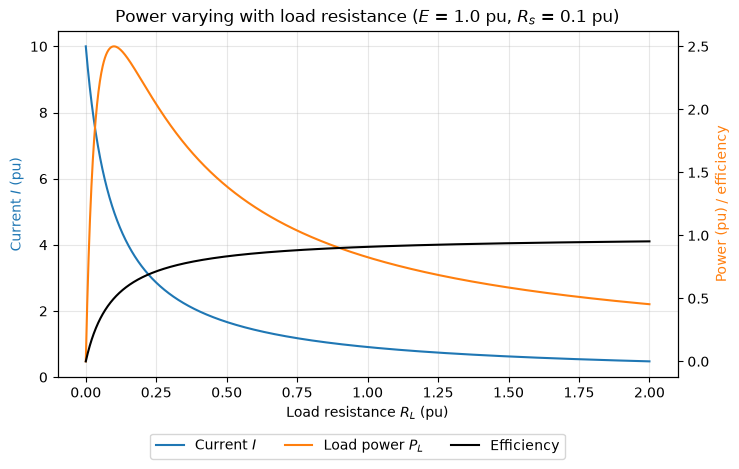

In [29]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(results_R['RL'], results_R['I'], color='tab:blue', label='Current $I$')
ax1.set_xlabel('Load resistance $R_L$ (pu)')
ax1.set_ylabel('Current $I$ (pu)', color='tab:blue')

ax2 = ax1.twinx()   # power and efficiency share the right-hand axis, as on the slide
ax2.plot(results_R['RL'], results_R['PL'], color='tab:orange', label='Load power $P_L$')
ax2.plot(results_R['RL'], results_R['eta'], color='black', label='Efficiency')
ax2.set_ylabel('Power (pu) / efficiency', color='tab:orange')

ax1.set_title('Power varying with load resistance ($E$ = 1.0 pu, $R_s$ = 0.1 pu)')
ax1.grid(alpha=0.3)
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3)
plt.show()

# tip: ax1.set_xscale('log') (with RL starting at 0.001) spreads out the low-resistance side

### 2) When is the power in the load equal to 1 pu ?


In [30]:
# solve the quadratic equation for R_L
# P = E**2 * RL / (Rs + RL)**2   ->   P*(Rs + RL)**2 = E**2 * RL
#   ->   P*RL**2 + (2*P*Rs - E**2)*RL + P*Rs**2 = 0
P = 1.0
RL_roots = np.roots([P, 2 * P * Rs - E**2, P * Rs**2])
print("RL for P_L = 1 pu:  ", RL_roots)
print("Efficiency at each: ", RL_roots / (Rs + RL_roots))

RL for P_L = 1 pu:   [0.78729833 0.01270167]
Efficiency at each:  [0.88729833 0.11270167]


### 3) What is the maximum power transfer possible? Why?

Differentiate the power equation with respect to $R_{L}$ and set it equal to zero.


In [31]:
# inspect from the results
print(results_R.loc[results_R['PL'].idxmax()])

# P = E**2 * RL / (Rs + RL)**2
# dP/dRL = E**2 * [(Rs + RL)**2 - 2*RL*(Rs + RL)] / (Rs + RL)**4 = E**2 * (Rs - RL) / (Rs + RL)**3 = 0   ->   RL = Rs
RL_max = Rs
P_max_R = E**2 * RL_max / (Rs + RL_max)**2      # = E**2 / (4*Rs)
print(f"\nAnalytical: RL = {RL_max} pu, P_max = {P_max_R:.2f} pu, efficiency = {RL_max / (Rs + RL_max):.0%}")

RL     0.1
I      5.0
VL     0.5
PL     2.5
eta    0.5
Name: 100, dtype: float64

Analytical: RL = 0.1 pu, P_max = 2.50 pu, efficiency = 50%


### 4. What is the power in the load for 95% efficiency? What is $R_{L}$ ?

In [32]:
# efficiency = RL / (Rs + RL) = 0.95   ->   RL = 0.95*Rs / (1 - 0.95)
eta_target = 0.95
RL_95 = eta_target * Rs / (1 - eta_target)
I_95R = E / (Rs + RL_95)
P_95R = I_95R**2 * RL_95
print(f"95% efficiency: RL = {RL_95:.2f} pu, I = {I_95R:.2f} pu, VL = {I_95R * RL_95:.2f} pu, P_L = {P_95R:.3f} pu")

95% efficiency: RL = 1.90 pu, I = 0.50 pu, VL = 0.95 pu, P_L = 0.475 pu


### 5. If E now increases to 1.05 pu, what is the power in the load, for the conditions of part 4.

In [33]:
E = 1.05
# same load as part 4 -> same load resistance RL = 1.9 pu
I_newR = E / (Rs + RL_95)
P_newR = I_newR**2 * RL_95
print(f"E = {E} pu: I = {I_newR:.4f} pu, P_L = {P_newR:.3f} pu, efficiency = {RL_95 / (Rs + RL_95):.0%}")

E = 1.05 pu: I = 0.5250 pu, P_L = 0.524 pu, efficiency = 95%


In [34]:
# summary: both viewpoints give the same answers
summary = pd.DataFrame({
    'Voltage view':    [f"VL = {VL_roots[0]:.3f} or {VL_roots[1]:.3f} pu",
                        f"{P_max:.1f} pu at VL = {VL_max} pu",
                        f"{P_95:.3f} pu at VL = {VL_95:.2f} pu",
                        f"{P_new:.3f} pu"],
    'Resistance view': [f"RL = {RL_roots[0]:.3f} or {RL_roots[1]:.4f} pu",
                        f"{P_max_R:.1f} pu at RL = {RL_max} pu",
                        f"{P_95R:.3f} pu at RL = {RL_95:.2f} pu",
                        f"{P_newR:.3f} pu"]},
    index=['Q2: P_L = 1 pu', 'Q3: maximum power', 'Q4: 95% efficiency', 'Q5: E = 1.05 pu'])
summary

,Voltage view,Resistance view
Q2: P_L = 1 pu,VL = 0.887 or 0.113 pu,RL = 0.787 or 0.0127 pu
Q3: maximum power,2.5 pu at VL = 0.5 pu,2.5 pu at RL = 0.1 pu
Q4: 95% efficiency,0.475 pu at VL = 0.95 pu,0.475 pu at RL = 1.90 pu
Q5: E = 1.05 pu,0.524 pu,0.524 pu
